In [1]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
plt.style.use(['science', 'no-latex'])

from pybaselines import Baseline, utils
from datetime import datetime, timezone
# from scipy.optimize import curve_fit
# from scipy.signal import savgol_filter
# from scipy.ndimage import binary_dilation
from scipy.signal import find_peaks

from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

In [2]:
# configuration for the plots
plt.style.use(['science', 'no-latex'])

plt.rcParams.update({
    "axes.labelsize": 14,  # Font size for axis labels
    "xtick.labelsize": 16,  # Font size for x-axis tick labels
    "ytick.labelsize": 16   # Font size for y-axis tick labels
})   

plt.rcParams['axes.unicode_minus'] = False


# Load the data

In [3]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

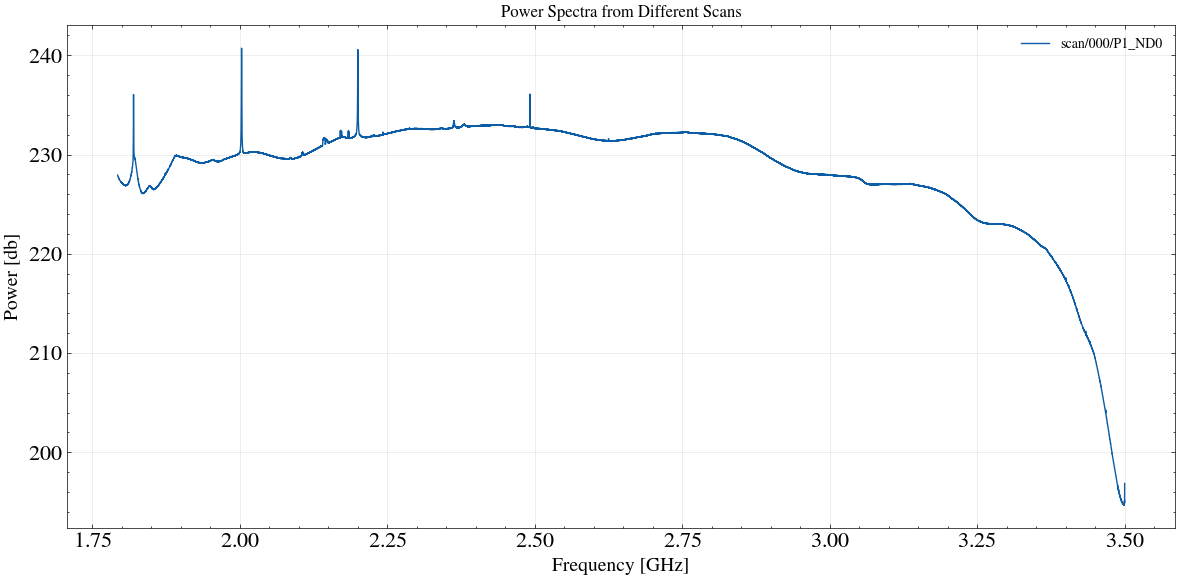

In [4]:
# Select different group os data

groups = [
    "scan/000/P1_ND0",
    # "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]


# plot the power spectrum
with h5py.File(filename,'r') as f:
    for g in groups:
        spectrum = f[f"{g}/spectrum"][:,1600:-1]
        freq = f[f"{g}/frequency"][1600:-1] / 1e9

        # Average over time axis
        mean_spectrum = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

        # Plot
        plt.figure(figsize=(12,6))
        plt.plot(freq, mean_spectrum, label=g)

        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [db]")
        plt.title("Power Spectra from Different Scans")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [5]:
mean_spectrum.shape

(63936,)

In [6]:
# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method:Asymmetric Least Square

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    the signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline



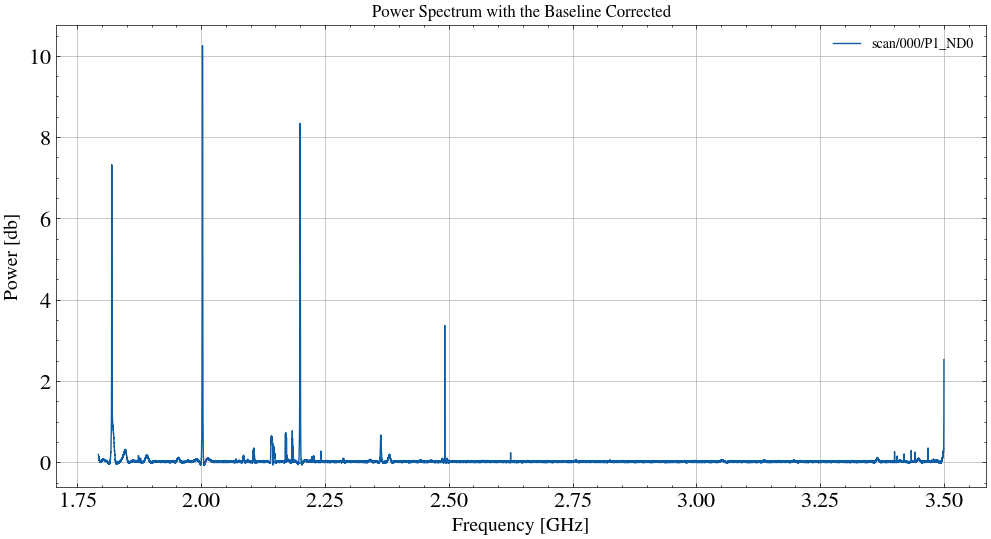

In [7]:
for g in groups:
    power_base_core = base_correction(freq, mean_spectrum) # Power with the baseline corrected!

    plt.figure(figsize=(12, 6))

    plt.plot(freq, power_base_core, label=g)
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.title("Power Spectrum with the Baseline Corrected")
    plt.grid()
    plt.legend()
    plt.show()

This is your input signal, likely a 1D NumPy array of power values (in dB or linear units) corresponding to frequency channels.

You want to find where the signal exhibits local maxima that might correspond to RFI spikes or real astrophysical features.

⚙️ height=...

This parameter sets a minimum height threshold for what counts as a “peak.”
Peaks below this value are ignored.

You defined:
$
height = MAD(power_base_core) + np.std(power_base_core)
$

Here’s what that means:

MAD = Median Absolute Deviation — a robust measure of noise level, less sensitive to outliers than standard deviation:


np.std(power_base_core) = standard deviation of the data — gives an estimate of the noise scatter.

By adding them together, you set the detection threshold at roughly:

Threshold = Typical Noise Level + Expected Variation


This ensures that small random fluctuations aren’t falsely flagged as peaks — only strong, significant spikes (e.g., RFI features) are detected.

⚙️ distance=10

This defines the minimum horizontal distance (in samples) between neighboring peaks.

If two peaks are closer than 10 data points apart, only the highest one is kept.

In a frequency spectrum, this avoids detecting multiple peaks within one broad RFI feature.

In other words: don’t call every little wiggle a separate peak.

⚙️ prominence=1.5

Prominence measures how much a peak stands out relative to its surroundings — not just its height, but also its contrast against nearby valleys.

Mathematically, the prominence of a peak is the vertical distance between the peak height and the lowest contour line that encloses it but contains no higher peak.

By setting prominence=1.5, you require that:

peak height
−
local background
>
1.5
peak height−local background>1.5

This filters out small, insignificant bumps and keeps only strong, well-defined peaks.

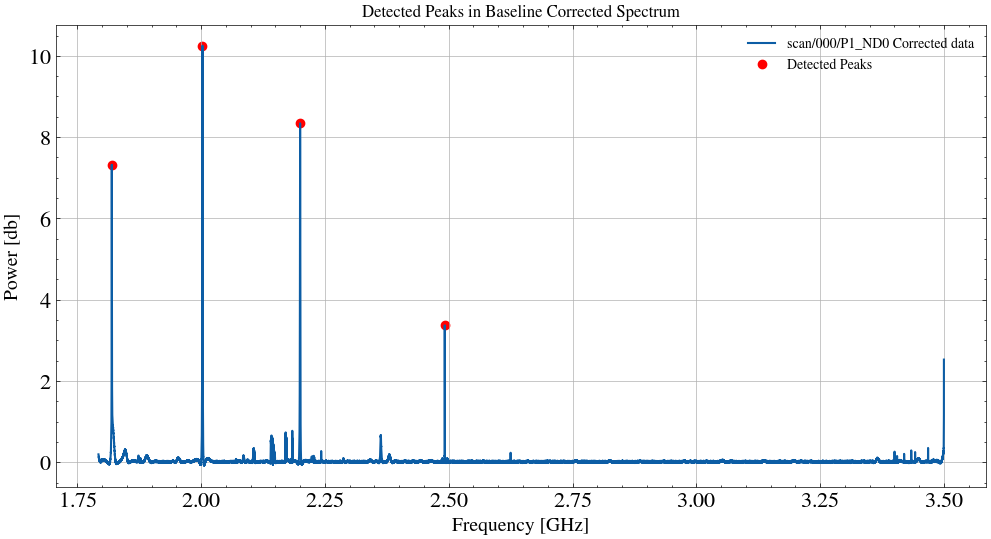

Detected peak frequencies (GHz): ['1.82', '2.003', '2.2', '2.492']


In [8]:
# lets find peaks
for g in groups:
        
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + np.std(power_base_core), 
                                distance=10,
                                prominence=1.5
                                )


    plt.figure(figsize=(12, 6))
    plt.plot(freq, power_base_core, label=f'{g} Corrected data', lw=1.5)
    plt.scatter(freq[peaks], power_base_core[peaks], color='red', label='Detected Peaks')
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.title("Detected Peaks in Baseline Corrected Spectrum")
    plt.grid()
    plt.legend()
    plt.show()

    formatted_freqs = [f"{f:.4}" for f in freq[peaks]]
    print(f"Detected peak frequencies (GHz): {formatted_freqs}")

In [9]:
# Evaluate the performance of the model
def reduce_chi_square(model,frequency,power, yerr=None):

    """
    Compute reduced chi-square for a fitted astropy model.

    fit_model : astropy model (already fitted)
    frequency     : array, independent variable (frequency)
    power     : array, observed data (power)
    yerr  : array or float, optional measurement uncertainties.
            If None, use std of y as uniform error.
    """

    fit_model = model(power)
    residuals = power - fit_model

    if yerr is None:
        yerr = np.std(power) 
        
    chi2 = np.sum((residuals / yerr)**2)   
    chi2_red = chi2 / (len(frequency) - len(model.param_names))

    return chi2_red



In [10]:
# automate power epectrum inspection

# Gaussian Fitting

def gaussian_fit_RFI (frequency, power, tie):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)

        # Calculate the Root Mean Squared Error (RMSE)
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Calculate the Chi-square
        chi2 = np.sum(residuals / np.std(power)**2)
        reduce_chi_square = chi2 / (len(frequency) - len(fitted_model.param_names))
        print(f'The reduce_chi-square is: {reduce_chi_square:.3f}')

        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)


        # Calculate the Root Mean Squared Error (RMSE)
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Calculate the Chi-square
        chi2 = np.sum(residuals / np.std(power)**2)
        reduce_chi_square = chi2 / (len(power) - len(fitted_model.param_names))
        print(f'The Chi-square is: {reduce_chi_square:.3f}')

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = 'Gaussian Fit'


    # entreduce a subplot of residual and put the horizontal line for the mean and RMSE
    
    plt.figure(figsize=(12, 6))
    plt.plot(frequency, power, '.', label="Data")
    plt.plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()




The Root Mean Squared Error: 0.320
The Chi-square is: 0.014
Number off corrupted channels: 38.0


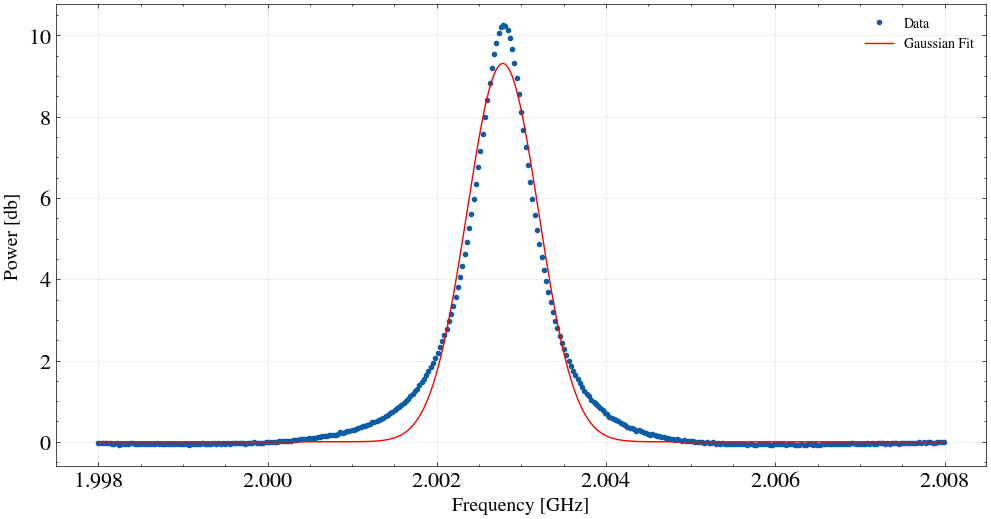

In [11]:
# define the window
mask1 = (freq > 1.807) & (freq < 1.835) 
mask2 = (freq > 1.998) & (freq < 2.008) 
mask3 = (freq > 2.195) & (freq < 2.204) 
mask4 = (freq > 2.491) & (freq < 2.493) 

fitted = gaussian_fit_RFI(freq[mask2], power_base_core[mask2], tie=False)




In [12]:
sigma = np.std(power_base_core[mask1])
sigma

np.float32(0.90624624)

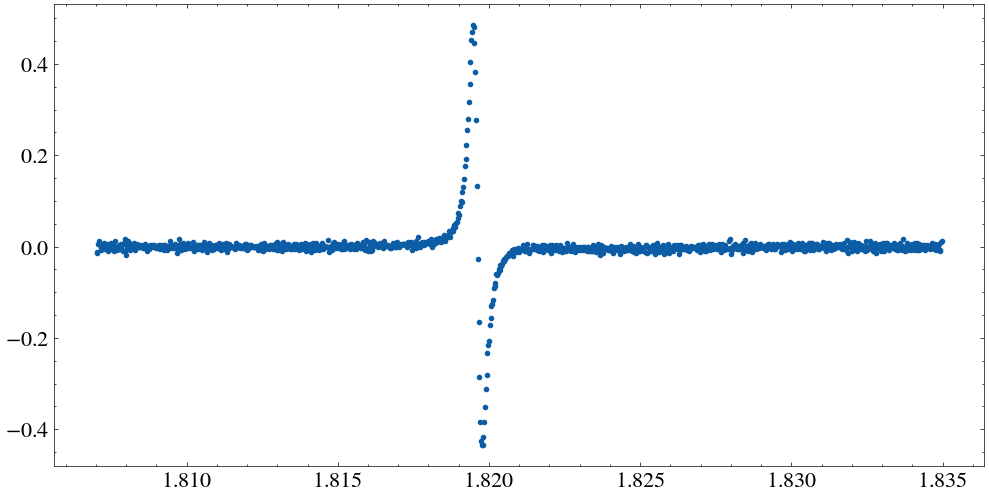

In [13]:
plt.figure(figsize=(12,6))
plt.plot(freq[mask1], np.gradient(power_base_core[mask1]), '.')

# use the gradient to find the edges of the RFI (read about it);
# to find where the power changes rapidly.

The Root Mean Squared Error: 0.262
The Chi-square is: 0.014
Number off corrupted channels: 38.0


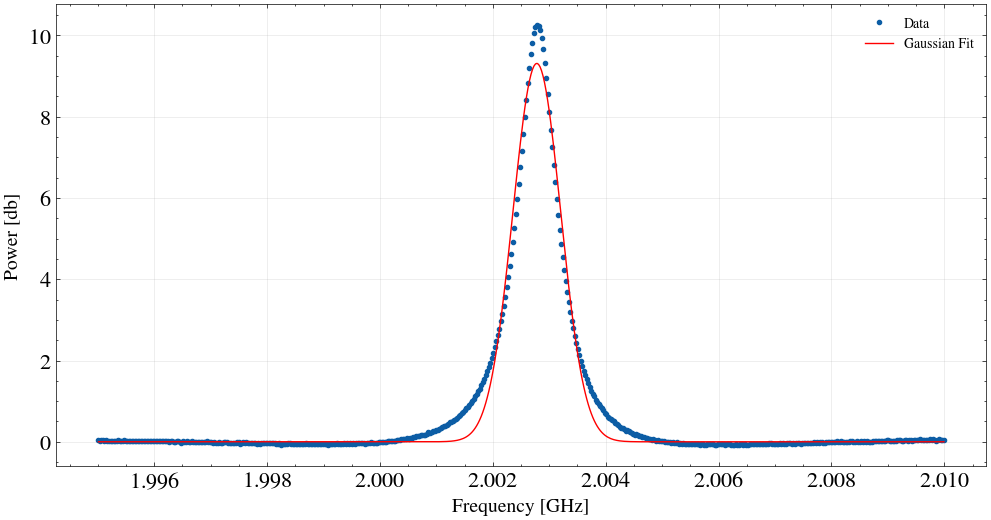

In [14]:
# define the window
mask01 = (freq > 1.812) & (freq < 1.8275)
mask02 = (freq > 1.995) & (freq < 2.01) 
mask03 = (freq > 2.197) & (freq < 2.203) 
mask04 = (freq > 2.491) & (freq < 2.493) 

fitted = gaussian_fit_RFI(freq[mask02], power_base_core[mask02], tie=False)




In [15]:

# Gaussian Fitting

def gaussian_fit(frequency, power, tie):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)

        # Calculate the Chi-square
        red_chi_square = reduce_chi_square(fitted_model,frequency,power)
        print(f'The reduce_chi-square is: {red_chi_square}')

        #residuals
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))

        # Calculate the Root Mean Squared Error (RMSE)
        print(f'The Root Mean Squared Error: {rmse}')

        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)

        #residuals
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        

        # Calculate the Chi-square
        chi_square = reduce_chi_square(fitted_model,frequency,power)
        print(f'The Chi-square is: {chi_square:.3f}')


        # # Calculate the Root Mean Squared Error (RMSE)
        # rmse = RMSE(power, fitted_model)
        print(f'The Root Mean Squared Error: {rmse:.3f}')

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans:.3f}')
        my_label = 'Gaussian Fit'


    # entreduce a subplot of residual and put the horizontal line for the mean and RMSE
    fig, ax = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    ax[0].plot(frequency, power, '.', label="Data")
    ax[0].plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    ax[0].set_ylabel("Power [db]")
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)

    
    # Residuals subplot
    ax[1].scatter(frequency, residuals, s=15, alpha=0.6, label="Residuals")
    ax[1].axhline(res_mean, color="orange", linestyle="--", lw=2, label=f"Mean = {res_mean:.3f}")
    ax[1].axhline(rmse, color="purple", linestyle="--", lw=2, label=f"RMSE = {rmse:.3f}")
    ax[1].axhline(-rmse, color="purple", linestyle="--", lw=2)  # symmetric RMSE band
    ax[1].set_xlabel("x")
    ax[1].set_ylabel("Residuals")
    ax[1].legend()




The Chi-square is: 1.174
The Root Mean Squared Error: 0.101
Number off corrupted channels: 2.000


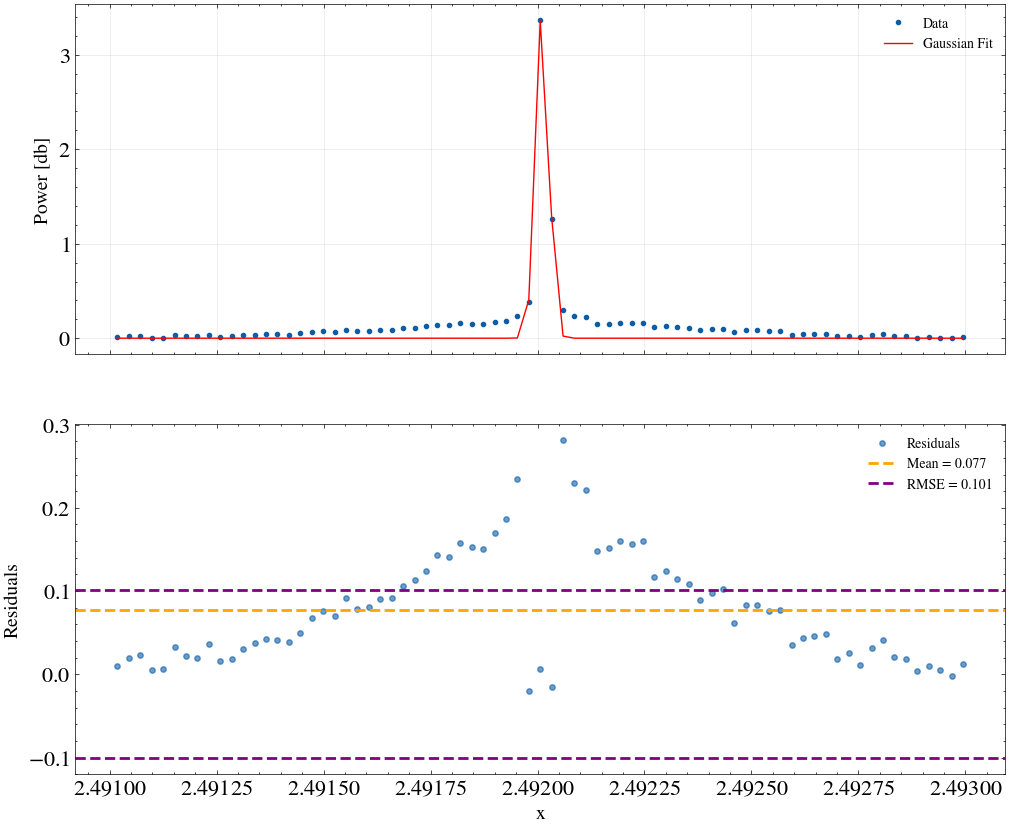

In [16]:
fitted = gaussian_fit(freq[mask4], power_base_core[mask4], tie=False)


# Quantify how wide an RFI peak is in frequency

In [17]:
# define the window
mask1 = (freq > 1.814) & (freq < 1.83)
mask2 = (freq > 1.998) & (freq < 2.008) 
mask3 = (freq > 2.197) & (freq < 2.203) 
mask4 = (freq > 2.491) & (freq < 2.493) 

def quantify_RFI_width(freq, power):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"Start Frequency: {start_freq:.4f} GHz")
    print(f"End Frequency: {end_freq:.4f} GHz")
    print(f"Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB")


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # channel width
    chans = ((end_freq - start_freq) / delta_frequency)

    print(f'Number off corrupted channels: {chans: .1f}')


    # --- Plot results ---
    plt.figure(figsize=(8,5))
    plt.plot(freq, power, '.', color='steelblue', label='Data')
    plt.axvline(start_freq, color='green', linestyle='--', label='Start')
    plt.axvline(peak_freq, color='red', linestyle='-', label='Peak')
    plt.axvline(end_freq, color='orange', linestyle='--', label='End')
    plt.xlabel('Frequency [GHz]', fontsize=22)
    plt.ylabel('Power [dB]', fontsize=22)
    plt.legend(fontsize=17)
    plt.grid(True)
    plt.legend(fontsize=17)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.show()

    return start_freq, end_freq, peak_freq, peak_power




Start Frequency: 1.8164 GHz
End Frequency: 1.8271 GHz
Peak Frequency: 1.8196 GHz with Power: 7.3196 dB
Number off corrupted channels:  400.0


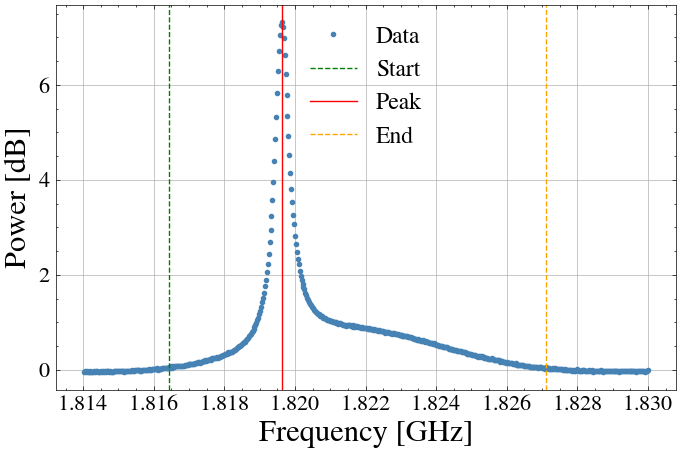

(np.float64(1.8164234161376953),
 np.float64(1.8271045684814453),
 np.float64(1.8196277618408203),
 np.float32(7.319641))

In [18]:
quantify_RFI_width(freq[mask1], power_base_core[mask1])

Start frequency (rise above zero): 1.816423 GHz, Power: 0.057 dB
Peak frequency: 1.819628 GHz, Power: 7.320 dB
End frequency (back to zero): 1.827105 GHz, Power: 0.050 dB
Number off corrupted channels:  400.0
-----------------------------------
Start frequency (rise above zero): 2.000326 GHz, Power: 0.051 dB
Peak frequency: 2.002783 GHz, Power: 10.251 dB
End frequency (back to zero): 2.004839 GHz, Power: 0.071 dB
Number off corrupted channels:  169.0
-----------------------------------


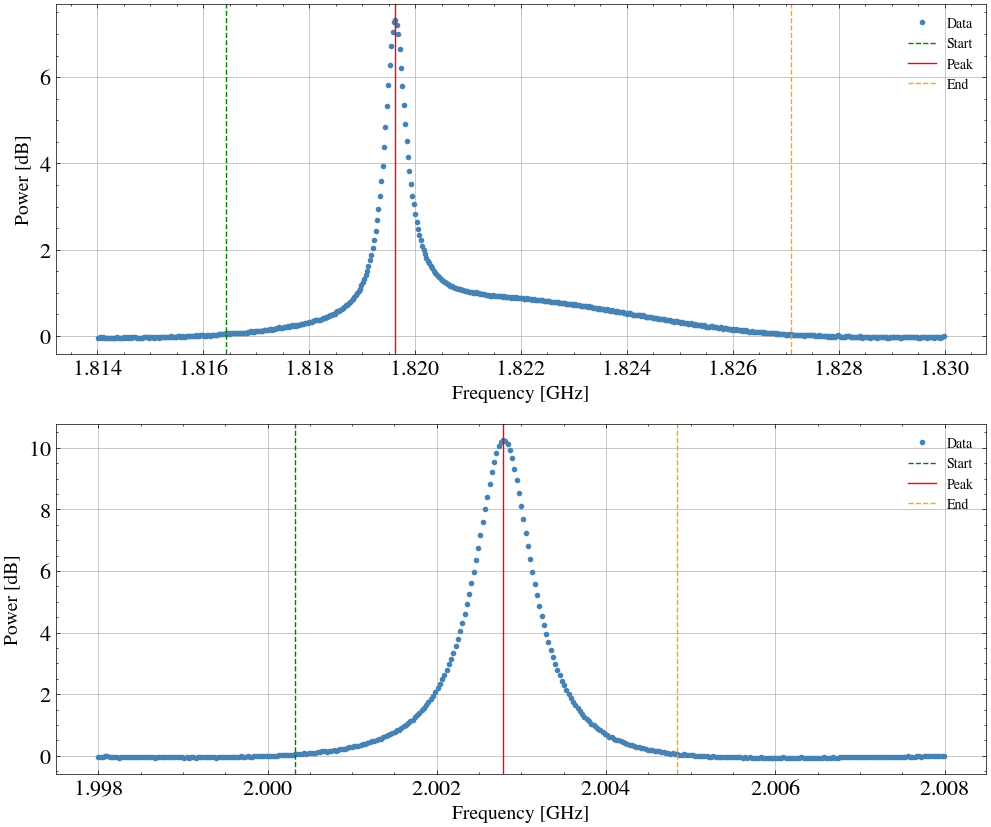

In [19]:
def quantify_RFI_width(freq, power, ax=None):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters
    ----------
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    ax : matplotlib.axes._axes.Axes, optional
        Axis to plot into. If None, creates a new figure.

    Returns
    -------
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """
    threshold = 0.05  # small threshold
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- Peak values ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]

    

    # --- Number of channels corrupted ---
    delta_frequency = (freq[1] - freq[0])
    chans = ((end_freq - start_freq) / delta_frequency)

    
    print(f"Start frequency (rise above zero): {start_freq:.6f} GHz, Power: {power[start_index]:.3f} dB")
    print(f"Peak frequency: {peak_freq:.6f} GHz, Power: {peak_power:.3f} dB")
    print(f"End frequency (back to zero): {end_freq:.6f} GHz, Power: {power[end_index]:.3f} dB")
    print(f'Number off corrupted channels: {chans: .1f}')
    print('-----------------------------------')



    # --- Plot ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.axvline(start_freq, color='green', linestyle='--', label='Start')
    ax.axvline(peak_freq, color='red', linestyle='-', label='Peak')
    ax.axvline(end_freq, color='orange', linestyle='--', label='End')
    ax.set_xlabel('Frequency [GHz]')
    ax.set_ylabel('Power [dB]')
    ax.legend()
    ax.grid(True)




    return start_freq, end_freq, peak_freq, peak_power

fig, ax = plt.subplots(2, 1, figsize=(12, 10))

quantify_RFI_width(freq[mask1], power_base_core[mask1], ax=ax[0])
quantify_RFI_width(freq[mask2], power_base_core[mask2], ax=ax[1])
#quantify_RFI_width(freq[mask3], power_base_core[mask3], ax=ax[2])
#quantify_RFI_width(freq[mask4], power_base_core[mask4], ax=ax[3])

plt.show()


Start frequency (rise above zero): 1.816423 GHz, Power: 0.057 dB
Peak frequency: 1.819628 GHz, Power: 7.320 dB
End frequency (back to zero): 1.827105 GHz, Power: 0.057 dB
Number off corrupted channels:  400.0


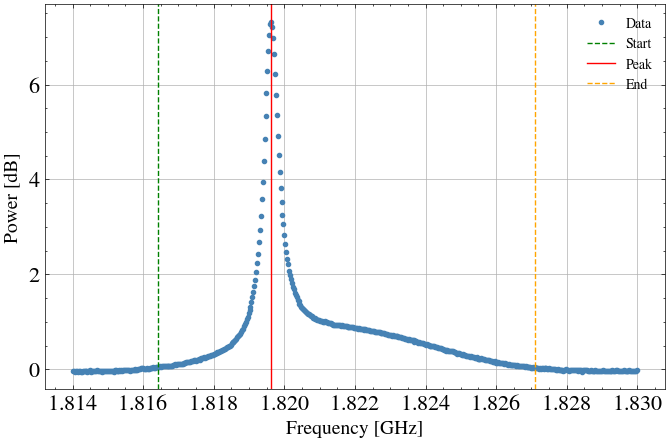

In [20]:
#Apply the mask on the varibales
freq_masked = freq[mask1]
power_masked = power_base_core[mask1]

# --- 1) Find where power rises above zero ---
threshold = 0.05  # small threshold to ignore noise near zero
above_threshold = np.where(power_masked > threshold)[0]

if len(above_threshold) > 0:
    start_index = above_threshold[0]
    end_index = above_threshold[-1]
    start_freq = freq_masked[start_index]
    end_freq = freq_masked[end_index]
else:
    start_freq = end_freq = np.nan
    print("No significant power detected in the masked range.")

# --- 2) Find the frequency of the peak ---
peak_index = np.argmax(power_masked)
peak_freq = freq_masked[peak_index]
peak_power = power_masked[peak_index]

print(f"Start frequency (rise above zero): {start_freq:.6f} GHz, Power: {power_masked[start_index]:.3f} dB")
print(f"Peak frequency: {peak_freq:.6f} GHz, Power: {peak_power:.3f} dB")
print(f"End frequency (back to zero): {end_freq:.6f} GHz, Power: {power_masked[start_index]:.3f} dB")


# Number of channels corrupted.
delta_frequency = (freq[1] - freq[0])  # channel width
chans = ((end_freq - start_freq) / delta_frequency)

print(f'Number off corrupted channels: {chans: .1f}')


# --- 4) Plot results ---
plt.figure(figsize=(8,5))
plt.plot(freq[mask1], power_base_core[mask1], '.', color='steelblue', label='Data')
plt.axvline(start_freq, color='green', linestyle='--', label='Start')
plt.axvline(peak_freq, color='red', linestyle='-', label='Peak')
plt.axvline(end_freq, color='orange', linestyle='--', label='End')
plt.xlabel('Frequency [GHz]')
plt.ylabel('Power [dB]')
plt.legend()
plt.grid(True)
plt.show()

# EMCEE implementation

In [21]:


def gaussian_model(x, amp, mu, sigma):
    return amp * np.exp(-0.5 * ((x - mu) / sigma)**2)

def model_1gauss(theta, x):
    amp, mu, sigma = theta
    return gaussian_model(x, amp, mu, sigma)

def model_2gauss(theta, x, tie=False):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        g1 = gaussian_model(x, amp1, mu, sigma1)
        g2 = gaussian_model(x, amp2, mu, sigma2)
    else:
        amp1, mu1, sigma1, amp2, mu2, sigma2 = theta
        g1 = gaussian_model(x, amp1, mu1, sigma1)
        g2 = gaussian_model(x, amp2, mu2, sigma2)
    return g1 + g2

def emcee_gaussian_fit_RFI(frequency, power, tie=False, two_gauss=False,
                           nwalkers=32, nsteps=1200, burn=400, progress=True):
    """
    Fit 1 or 2 Gaussians using emcee MCMC with robust initialization.
    """
    import emcee

    x = np.array(frequency)
    y = np.array(power)
    dx = np.median(np.diff(x))

    # --- Initial Guesses ---
    peak_idx = np.argmax(y)
    peak_amp = y[peak_idx]
    peak_mu = x[peak_idx]
    sigma_narrow = max(5 * dx, 1e-6)
    sigma_broad = 0.01 if two_gauss else None
    median_amp = np.median(y)
    amp_broad = max((peak_amp - median_amp) / 5.0, 1e-6)

    # ========== Priors & Likelihood ==========
    if not two_gauss:
        def lnprior(theta):
            amp, mu, sigma, ln_j = theta
            if amp <= 0 or sigma <= 0:
                return -np.inf
            if mu < x.min() or mu > x.max():
                return -np.inf
            if not (-20 < ln_j < 5):
                return -np.inf
            return 0.0

        def lnlike(theta):
            amp, mu, sigma, ln_j = theta
            model = model_1gauss((amp, mu, sigma), x)
            j = np.exp(ln_j)
            resid = y - model
            var = np.var(y - np.median(y)) + j**2
            return -0.5 * np.sum(resid**2 / var + np.log(2*np.pi*var))

        def lnprob(theta):
            lp = lnprior(theta)
            if not np.isfinite(lp):
                return -np.inf
            return lp + lnlike(theta)

        ndim = 4
        initial_guess = [peak_amp, peak_mu, sigma_narrow, np.log(np.std(y) * 1e-2)]

    else:
        if tie:
            def lnprior(theta):
                amp1, mu, sigma1, amp2, sigma2, ln_j = theta
                if amp1 <= 0 or amp2 <= 0 or sigma1 <= 0 or sigma2 <= 0:
                    return -np.inf
                if mu < x.min() or mu > x.max():
                    return -np.inf
                if not (-20 < ln_j < 5):
                    return -np.inf
                return 0.0

            def lnlike(theta):
                amp1, mu, sigma1, amp2, sigma2, ln_j = theta
                model = model_2gauss((amp1, mu, sigma1, amp2, sigma2), x, tie=True)
                j = np.exp(ln_j)
                resid = y - model
                var = np.var(y - np.median(y)) + j**2
                return -0.5 * np.sum(resid**2 / var + np.log(2*np.pi*var))

            def lnprob(theta):
                lp = lnprior(theta)
                if not np.isfinite(lp):
                    return -np.inf
                return lp + lnlike(theta)

            ndim = 6
            initial_guess = [peak_amp, peak_mu, sigma_narrow, amp_broad, sigma_broad, np.log(np.std(y) * 1e-2)]

        else:
            def lnprior(theta):
                amp1, mu1, sigma1, amp2, mu2, sigma2, ln_j = theta
                if amp1 <= 0 or amp2 <= 0 or sigma1 <= 0 or sigma2 <= 0:
                    return -np.inf
                if mu1 < x.min() or mu1 > x.max() or mu2 < x.min() or mu2 > x.max():
                    return -np.inf
                if not (-20 < ln_j < 5):
                    return -np.inf
                return 0.0

            def lnlike(theta):
                amp1, mu1, sigma1, amp2, mu2, sigma2, ln_j = theta
                model = model_2gauss((amp1, mu1, sigma1, amp2, mu2, sigma2), x, tie=False)
                j = np.exp(ln_j)
                resid = y - model
                var = np.var(y - np.median(y)) + j**2
                return -0.5 * np.sum(resid**2 / var + np.log(2*np.pi*var))

            def lnprob(theta):
                lp = lnprior(theta)
                if not np.isfinite(lp):
                    return -np.inf
                return lp + lnlike(theta)

            ndim = 7
            initial_guess = [peak_amp, peak_mu, sigma_narrow, amp_broad, peak_mu + 0.02, sigma_broad, np.log(np.std(y) * 1e-2)]

    # ========== Robust Initialization ==========
    p0 = []
    for i in range(nwalkers):
        walker = []
        for val in initial_guess:
            spread = 0.1 * (abs(val) if val != 0 else 1.0)  # 10% jitter
            walker.append(val + spread * np.random.randn())
        p0.append(walker)
    p0 = np.array(p0)

    # ========== Run Sampler ==========
    sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob)
    pos, _, _ = sampler.run_mcmc(p0, burn, progress=progress)  # burn-in
    sampler.reset()
    sampler.run_mcmc(pos, nsteps, progress=progress)           # production
    samples = sampler.get_chain(flat=True)

    # ========== Median Model + Credible Interval ==========
    med = np.median(samples, axis=0)
    npost = min(200, len(samples))
    idxs = np.random.choice(np.arange(len(samples)), size=npost, replace=False)
    model_draws = []
    for idx in idxs:
        params = samples[idx]
        if not two_gauss:
            amp, mu, sigma, ln_j = params
            model_draws.append(model_1gauss((amp, mu, sigma), x))
        else:
            if tie:
                amp1, mu, sigma1, amp2, sigma2, _ = params
                model_draws.append(model_2gauss((amp1, mu, sigma1, amp2, sigma2), x, tie=True))
            else:
                amp1, mu1, sigma1, amp2, mu2, sigma2, _ = params
                model_draws.append(model_2gauss((amp1, mu1, sigma1, amp2, mu2, sigma2), x, tie=False))

    model_draws = np.array(model_draws)
    lower = np.percentile(model_draws, 16, axis=0)
    upper = np.percentile(model_draws, 84, axis=0)
    median_model_vals = np.percentile(model_draws, 50, axis=0)

    # ========== Plot ==========
    plt.figure(figsize=(10, 5))
    plt.plot(x, y, '.', label='Data')
    plt.plot(x, median_model_vals, '-', label='Median model')
    plt.fill_between(x, lower, upper, alpha=0.3, label='16-84% credible interval')
    plt.xlabel("Frequency")
    plt.ylabel("Power")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return {
        'sampler': sampler,
        'samples': samples,
        'median_params': med,
        'x': x,
        'median_model': median_model_vals,
        'lower': lower,
        'upper': upper,
    }


In [22]:
# Run emcee fit on the synthetic data (two_gauss True, tie True)
try:
    res = emcee_gaussian_fit_RFI(freq[mask1], power_base_core[mask1], tie=True, two_gauss=True,
                                 nwalkers=32, nsteps=800, burn=200, progress=False)
except ImportError as e:
    print(str(e))
    print("\nThe function source is available in the cell above; install emcee to run it locally.")

No module named 'emcee'

The function source is available in the cell above; install emcee to run it locally.


In [23]:


# --- Gaussian models ---
def gaussian(x, amp, mu, sigma):
    return amp * np.exp(-0.5 * ((x - mu)/sigma)**2)

def double_gaussian(x, amp1, mu, sigma1, amp2, sigma2):
    return gaussian(x, amp1, mu, sigma1) + gaussian(x, amp2, mu, sigma2)

# --- log-likelihood ---
def log_likelihood(theta, x, y, yerr, tie):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        model = double_gaussian(x, amp1, mu, sigma1, amp2, sigma2)
    else:
        amp, mu, sigma = theta
        model = gaussian(x, amp, mu, sigma)
    return -0.5 * np.sum(((y - model)/yerr)**2)

# --- priors ---
def log_prior(theta, tie):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        if (0 < sigma1 < 1) and (0 < sigma2 < 1) and (amp1 > 0) and (amp2 > 0):
            return 0.0
        return -np.inf
    else:
        amp, mu, sigma = theta
        if (0 < sigma < 1) and (amp > 0):
            return 0.0
        return -np.inf

def log_probability(theta, x, y, yerr, tie):
    lp = log_prior(theta, tie)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr, tie)

# --- main function ---
def gaussian_fit_emcee(frequency, power, tie=False, nwalkers=50, nsteps=2000, burnin=500):
    """ Fit Gaussian(s) using emcee + show fit, uncertainty band, and corner plot """

    # noise estimate
    yerr = np.std(power) * 0.1  

    # Initial guess
    peak_idx = np.argmax(power)
    peak_amp = power[peak_idx]
    peak_mu = frequency[peak_idx]
    delta_f = (frequency[1] - frequency[0])

    if tie:
        initial = np.array([peak_amp, peak_mu, 5*delta_f, peak_amp/2, 10*delta_f])
        ndim = len(initial)
    else:
        initial = np.array([peak_amp, peak_mu, 5*delta_f])
        ndim = len(initial)

    # spread walkers
    pos = initial + 1e-4 * np.random.randn(nwalkers, ndim)

    # sampler
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(frequency, power, yerr, tie))
    sampler.run_mcmc(pos, nsteps, progress=True)

    # discard burn-in
    flat_samples = sampler.get_chain(discard=burnin, thin=10, flat=True)

    # median fit
    med_params = np.median(flat_samples, axis=0)

    # --- Plot fit with uncertainties ---
    plt.figure(figsize=(12, 6))
    plt.plot(frequency, power, "k.", label="Data")

    # random draws
    for s in flat_samples[np.random.randint(len(flat_samples), size=100)]:
        if tie:
            amp1, mu, sigma1, amp2, sigma2 = s
            plt.plot(frequency, double_gaussian(frequency, amp1, mu, sigma1, amp2, sigma2),
                     color="gray", alpha=0.05)
        else:
            amp, mu, sigma = s
            plt.plot(frequency, gaussian(frequency, amp, mu, sigma),
                     color="gray", alpha=0.05)

    # median fit
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = med_params
        plt.plot(frequency, double_gaussian(frequency, amp1, mu, sigma1, amp2, sigma2),
                 "r-", lw=2, label="Median fit")
    else:
        amp, mu, sigma = med_params
        plt.plot(frequency, gaussian(frequency, amp, mu, sigma),
                 "r-", lw=2, label="Median fit")

    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [dB]")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # --- Corner plot ---
    labels = ["amp1", "mu", "sigma1", "amp2", "sigma2"] if tie else ["amp", "mu", "sigma"]
    fig = corner.corner(flat_samples, labels=labels, truths=med_params, show_titles=True)
    plt.show()

    return med_params, flat_samples


In [24]:
# Run emcee fit on the synthetic data (two_gauss True, tie True)
try:
    res = gaussian_fit_emcee(freq[mask2], power_base_core[mask2], tie=False,
                                 nwalkers=32, nsteps=800)
except ImportError as e:
    print(str(e))
    print("\nThe function source is available in the cell above; install emcee to run it locally.")

NameError: name 'emcee' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner

# --- Gaussian models ---
def gaussian(x, amp, mu, sigma):
    return amp * np.exp(-0.5 * ((x - mu)/sigma)**2)

def double_gaussian(x, amp1, mu, sigma1, amp2, sigma2):
    return gaussian(x, amp1, mu, sigma1) + gaussian(x, amp2, mu, sigma2)

# --- log-likelihood ---
def log_likelihood(theta, x, y, yerr, tie):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        model = double_gaussian(x, amp1, mu, sigma1, amp2, sigma2)
    else:
        amp, mu, sigma = theta
        model = gaussian(x, amp, mu, sigma)
    return -0.5 * np.sum(((y - model)/yerr)**2)

# --- priors ---
def log_prior(theta, tie):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        if (0 < sigma1 < 1) and (0 < sigma2 < 1) and (amp1 > 0) and (amp2 > 0):
            return 0.0
        return -np.inf
    else:
        amp, mu, sigma = theta
        if (0 < sigma < 1) and (amp > 0):
            return 0.0
        return -np.inf

def log_probability(theta, x, y, yerr, tie):
    lp = log_prior(theta, tie)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr, tie)

# --- main function ---
def gaussian_fit_emcee(frequency, power, tie=False, nwalkers=50, nsteps=2000, burnin=500):
    """ Fit Gaussian(s) using emcee + show fit, credible interval band, and corner plot """

    # noise estimate
    yerr = np.std(power) * 0.1  

    # Initial guess
    peak_idx = np.argmax(power)
    peak_amp = power[peak_idx]
    peak_mu = frequency[peak_idx]
    delta_f = (frequency[1] - frequency[0])

    if tie:
        initial = np.array([peak_amp, peak_mu, 5*delta_f, peak_amp/2, 10*delta_f])
        ndim = len(initial)
    else:
        initial = np.array([peak_amp, peak_mu, 5*delta_f])
        ndim = len(initial)

    # spread walkers
    pos = initial + 1e-4 * np.random.randn(nwalkers, ndim)

    # sampler
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(frequency, power, yerr, tie))
    sampler.run_mcmc(pos, nsteps, progress=True)

    # discard burn-in
    flat_samples = sampler.get_chain(discard=burnin, thin=10, flat=True)

    # median fit
    med_params = np.median(flat_samples, axis=0)

    # --- Compute model distribution ---
    model_curves = []
    for s in flat_samples[np.random.randint(len(flat_samples), size=500)]:
        if tie:
            amp1, mu, sigma1, amp2, sigma2 = s
            model_curves.append(double_gaussian(frequency, amp1, mu, sigma1, amp2, sigma2))
        else:
            amp, mu, sigma = s
            model_curves.append(gaussian(frequency, amp, mu, sigma))
    model_curves = np.array(model_curves)

    # median & credible interval
    model_median = np.median(model_curves, axis=0)
    lower = np.percentile(model_curves, 16, axis=0)
    upper = np.percentile(model_curves, 84, axis=0)

    # --- Plot fit with uncertainty band ---
    plt.figure(figsize=(12, 6))
    plt.plot(frequency, power, "k.", label="Data")
    plt.plot(frequency, model_median, "r-", lw=2, label="Median fit")
    plt.fill_between(frequency, lower, upper, color="red", alpha=0.3, label="1σ credible interval")
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [dB]")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # --- Corner plot ---
    labels = ["amp1", "mu", "sigma1", "amp2", "sigma2"] if tie else ["amp", "mu", "sigma"]
    fig = corner.corner(flat_samples, labels=labels, truths=med_params, show_titles=True)
    plt.show()

    return med_params, flat_samples


You must install the tqdm library to use progress indicators with emcee
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 963 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:201: RuntimeWarning: Glyph 963 missing from current font.
  font.set_text(s, 0, flags=flags)


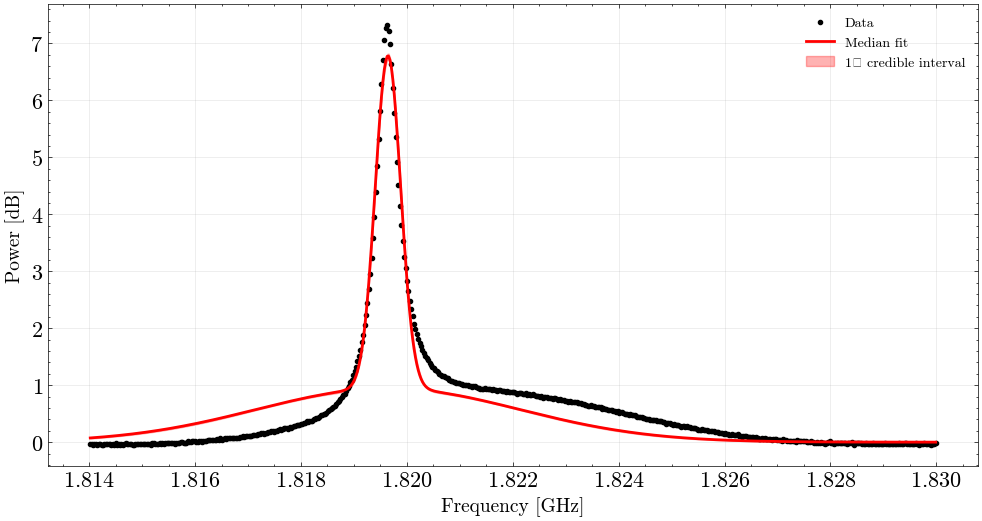

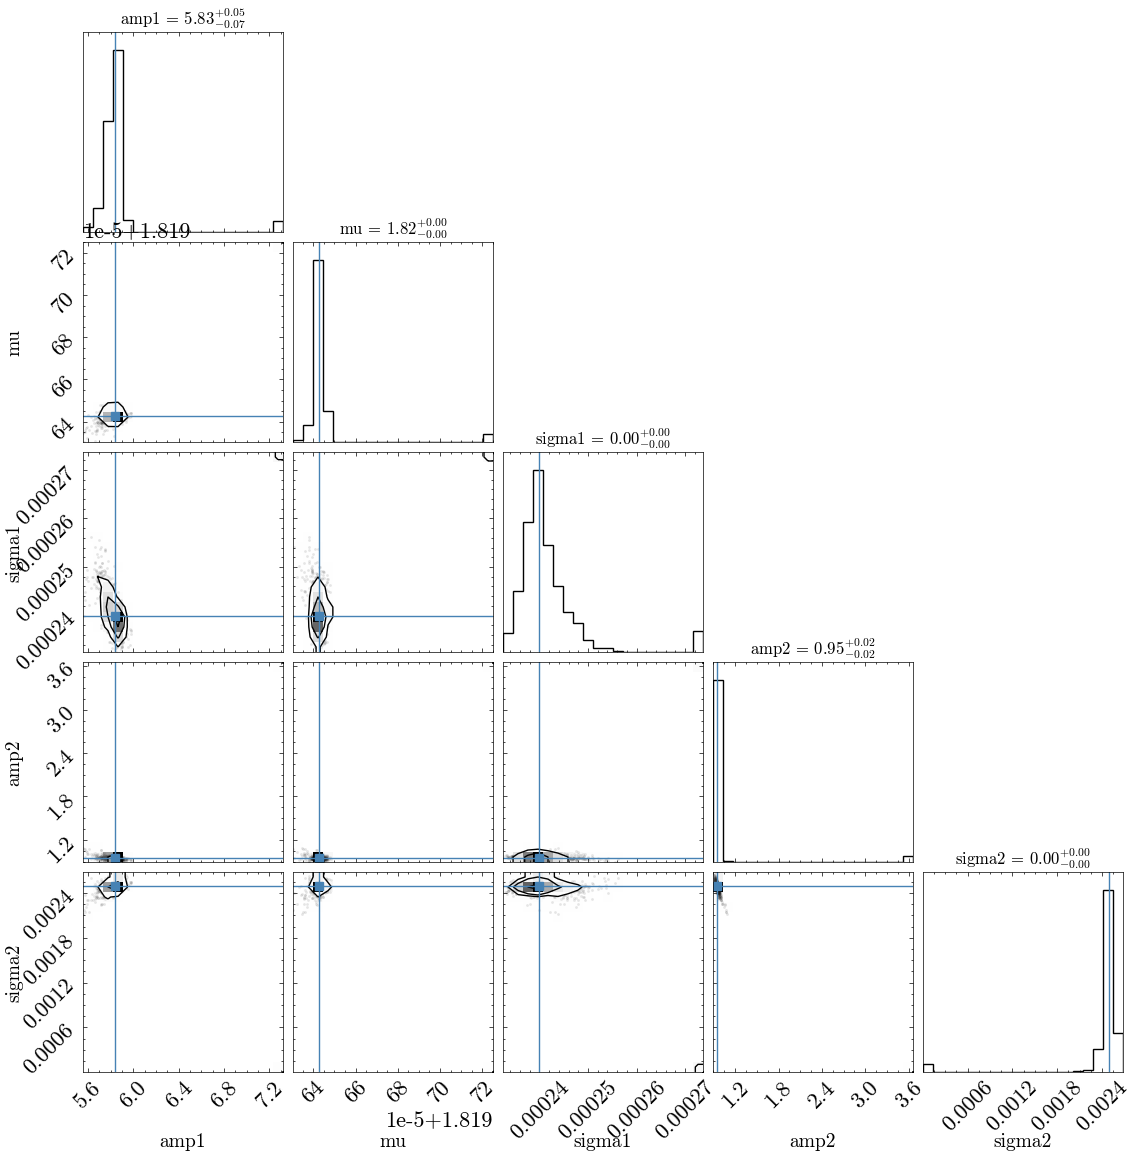

In [ ]:
# Run emcee fit on the synthetic data (two_gauss True, tie True)
try:
    res = gaussian_fit_emcee(freq[mask1], power_base_core[mask1], tie=True,
                                 nwalkers=32, nsteps=800)
except ImportError as e:
    print(str(e))
    print("\nThe function source is available in the cell above; install emcee to run it locally.")

# Bayesian Gaussian Fitting with MCMC (emcee)

This notebook demonstrates how to fit one or two Gaussian models to a power spectrum using **Bayesian inference** and the **MCMC sampler emcee**.  

Instead of a single best-fit (like least-squares), we obtain the **posterior probability distributions** of the parameters. This allows us to estimate **credible intervals (uncertainties)** and visualize correlations between parameters.

---

## 1. The Gaussian Models

We use two possible models:

### Single Gaussian
$$
G(x \mid A, \mu, \sigma) = A \exp\left(-\frac{1}{2} \left(\frac{x - \mu}{\sigma}\right)^2\right)
$$

where  
- \(A\) = amplitude  
- \(\mu\) = mean (center frequency)  
- \(\sigma\) = standard deviation (width)

---

### Double Gaussian (with tied mean)
$$
M(x) = A_1 \exp\left(-\frac{1}{2} \left(\frac{x - \mu}{\sigma_1}\right)^2\right)
+ A_2 \exp\left(-\frac{1}{2} \left(\frac{x - \mu}{\sigma_2}\right)^2\right)
$$

where the two Gaussians share the same center \(\mu\), but have different amplitudes and widths.

---

## 2. Bayesian Inference

We want the **posterior distribution** of parameters \(\theta\):

$$
p(\theta \mid x, y) \propto p(\theta) \, p(y \mid x, \theta)
$$

- \(p(\theta)\): Prior distribution (assumptions about parameters before seeing the data)  
- \(p(y \mid x, \theta)\): Likelihood function (how well the model fits the data)  
- \(p(\theta \mid x, y)\): Posterior distribution (updated belief about parameters after seeing the data)

---

### Likelihood

Assume Gaussian errors with standard deviation \(\sigma_y\). Then:

$$
\ln \mathcal{L}(\theta) = -\frac{1}{2} \sum_i \left( \frac{y_i - M(x_i \mid \theta)}{\sigma_y} \right)^2
$$

where \(M(x_i \mid \theta)\) is the model evaluated at frequency \(x_i\).

---

### Priors

We restrict parameters to physically meaningful ranges:

- Amplitudes \(A > 0\)  
- Widths \(\sigma > 0\) (limited to avoid unphysical broad fits)  
- Mean \(\mu\) free within the frequency range  

If parameters are outside allowed ranges, the prior is \(-\infty\).

---

### Posterior

The posterior is computed as:

$$
\ln p(\theta \mid x, y) = \ln p(\theta) + \ln \mathcal{L}(\theta)
$$

This is what the MCMC sampler evaluates.

---

## 3. MCMC Sampling

We use the **emcee** sampler:
- `nwalkers`: number of parallel chains exploring parameter space  
- `nsteps`: number of iterations (samples) per walker  
- `burn-in`: first steps discarded to remove initialization bias  

The result is a collection of samples from the posterior distribution.

---

## 4. Credible Intervals

From the posterior samples we can compute **credible intervals**:

- The **median** parameter values correspond to the "best" Bayesian estimate.  
- The **16th and 84th percentiles** define the **68% credible interval** (analogous to \(1\sigma\)).  

For the model curves:
- We evaluate the model at each frequency for many posterior samples.  
- At each frequency, we compute the **median** and the **16–84 percentile band**.  
- This gives a **shaded uncertainty band** around the median fit.

---

## 5. Python Implementation


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner

# --- Gaussian models ---
def gaussian(x, amp, mu, sigma):
    return amp * np.exp(-0.5 * ((x - mu)/sigma)**2)

def double_gaussian(x, amp1, mu, sigma1, amp2, sigma2):
    return gaussian(x, amp1, mu, sigma1) + gaussian(x, amp2, mu, sigma2)

# --- log-likelihood ---
def log_likelihood(theta, x, y, yerr, tie):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        model = double_gaussian(x, amp1, mu, sigma1, amp2, sigma2)
    else:
        amp, mu, sigma = theta
        model = gaussian(x, amp, mu, sigma)
    return -0.5 * np.sum(((y - model)/yerr)**2)

# --- priors ---
def log_prior(theta, tie):
    if tie:
        amp1, mu, sigma1, amp2, sigma2 = theta
        if (0 < sigma1 < 1) and (0 < sigma2 < 1) and (amp1 > 0) and (amp2 > 0):
            return 0.0
        return -np.inf
    else:
        amp, mu, sigma = theta
        if (0 < sigma < 1) and (amp > 0):
            return 0.0
        return -np.inf

def log_probability(theta, x, y, yerr, tie):
    lp = log_prior(theta, tie)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y, yerr, tie)

# --- fitting function ---
def gaussian_fit_emcee(frequency, power, tie=False, nwalkers=50, nsteps=2000, burnin=500):
    """ Fit Gaussian(s) using emcee + show fit, credible interval band, and corner plot """

    # noise estimate
    yerr = np.std(power) * 0.1  

    # Initial guess
    peak_idx = np.argmax(power)
    peak_amp = power[peak_idx]
    peak_mu = frequency[peak_idx]
    delta_f = (frequency[1] - frequency[0])

    if tie:
        initial = np.array([peak_amp, peak_mu, 5*delta_f, peak_amp/2, 10*delta_f])
        ndim = len(initial)
    else:
        initial = np.array([peak_amp, peak_mu, 5*delta_f])
        ndim = len(initial)

    # spread walkers
    pos = initial + 1e-4 * np.random.randn(nwalkers, ndim)

    # sampler
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(frequency, power, yerr, tie))
    sampler.run_mcmc(pos, nsteps, progress=True)

    # discard burn-in
    flat_samples = sampler.get_chain(discard=burnin, thin=10, flat=True)

    # median fit
    med_params = np.median(flat_samples, axis=0)

    # --- Compute model distribution ---
    model_curves = []
    for s in flat_samples[np.random.randint(len(flat_samples), size=500)]:
        if tie:
            amp1, mu, sigma1, amp2, sigma2 = s
            model_curves.append(double_gaussian(frequency, amp1, mu, sigma1, amp2, sigma2))
        else:
            amp, mu, sigma = s
            model_curves.append(gaussian(frequency, amp, mu, sigma))
    model_curves = np.array(model_curves)

    # median & credible interval
    model_median = np.median(model_curves, axis=0)
    lower = np.percentile(model_curves, 16, axis=0)
    upper = np.percentile(model_curves, 84, axis=0)

    # --- Plot fit with uncertainty band ---
    plt.figure(figsize=(12, 6))
    plt.plot(frequency, power, "k.", label="Data")
    plt.plot(frequency, model_median, "r-", lw=2, label="Median fit")
    plt.fill_between(frequency, lower, upper, color="blue", alpha=0.3, label="1$\sigma$ credible interval")
    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [dB]")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # --- Corner plot ---
    labels = ["amp1", "mu", "sigma1", "amp2", "sigma2"] if tie else ["amp", "mu", "sigma"]
    fig = corner.corner(flat_samples, labels=labels, truths=med_params, show_titles=True)
    plt.show()

    return med_params, flat_samples


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]


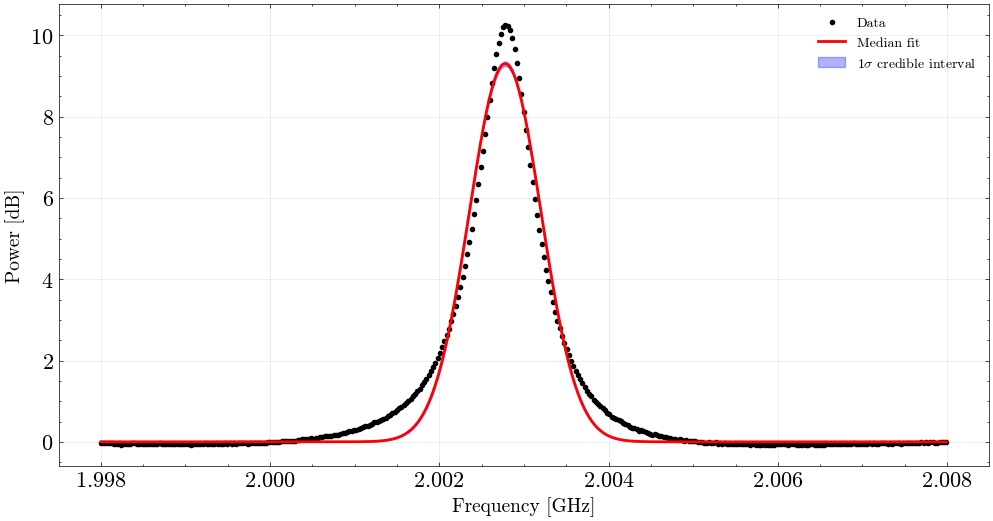

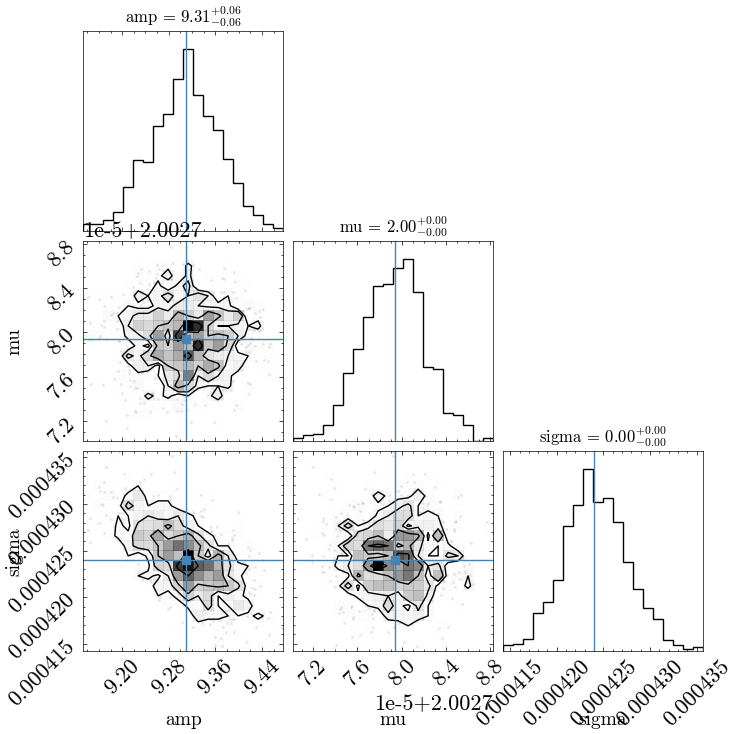

In [ ]:
# Run emcee fit on the synthetic data (two_gauss True, tie True)
try:
    res = gaussian_fit_emcee(freq[mask2], power_base_core[mask2], tie=False,
                                 nwalkers=32, nsteps=800)
except ImportError as e:
    print(str(e))
    print("\nThe function source is available in the cell above; install emcee to run it locally.")

---

## 6. Summary

- We defined **Gaussian models** (single and double).  
- We used **Bayesian inference** to estimate parameter posteriors.  
- We applied **MCMC sampling** (`emcee`) to explore parameter space.  
- We extracted **median values** and **credible intervals (16–84%)**.  
- We plotted the fit with a **shaded uncertainty band**.  
- We visualized parameter correlations with a **corner plot**.

This approach is more powerful than simple least-squares because it quantifies the full uncertainty and degeneracies between parameters.

---


`bayesian` -- lern and undertand what it does.